# PZ data challenge: task set 3

**Task set 3: non-representative training, plus COSMOS2020 many-band photo-z.** The reference redshift is:
- the spectroscopic redshift (`redshift`) for objects selected by a spectroscopic survey;
- `redshift_manyband` for objects selected only by COSMOS2020, whose `redshift` is NaN.

The COSMOS-only objects are the faint, test-like part of the training set, but they can only be scored against their many-band photo-z, so their metrics include the label noise.

This notebook only trains. For each of the four configurations of the task set (cardinal and flagship, 1yr and 10yr) it trains the CNN ensemble on the training file, holding out `VAL_FRAC` of it (split by `SEED`), and saves the trained ensemble as a single `.pkl` under its official name in `OUT_DIR` (the subtask 2 file, via `znn.save_ensemble_file`), shared by all four task-set notebooks. Everything that uses the models, the test-set p(z)s and the scores on the held-out objects, is in `pz_challenge_results.ipynb`, which predicts from these files.

The ensemble is trained with `znn.train_from_catalog`. Each member is trained on its own noise realization of the training photometry, redrawn from the catalogue's `_err` columns (the photometry as given if it has no errors), and on its own K-fold cut: member k validates on fold k and trains on the others. Every member starts from the pop-cosmos model shipped with znn. With `FROM_BASE = True` (the default), a base model is first trained on all the objects and each member is a copy of it fine-tuned on its realization and fold for `FINETUNE_EPOCHS` epochs at a constant `FINETUNE_LR`, which is cheaper per member.

Run this from the repo root with the `qp` conda env as the kernel. The filter curves are the ones shipped with RAIL, which `pz_data_challenge` installs.

## Configuration

In [1]:
from rail.utils.path_utils import find_rail_file

import znn  # run from the repo root so this picks up the local source

TASKSET = 3
SIMS = ["cardinal", "flagship"]
SCENARIOS = ["1yr", "10yr"]

DATA_DIR = "../pz_data_challenge/scripts/public"
# Training starting point: "popcosmos" (the pre-training shipped with znn) or None (from scratch). Each choice
# writes to its own directory, so runs with and without pre-training never overwrite each other.
PRETRAINING = "popcosmos"
# How the ensemble is trained (znn.train_from_catalog): every member on its own noise realization of the
# training photometry (the photometry as given if it has no errors) and its own K-fold cut (member k validates
# on fold k and trains on the others)
# True: train one base model on all the objects, then fine-tune a copy of it per member (its own realization
# and fold) at FINETUNE_LR for FINETUNE_EPOCHS, cheaper per member; False: every member trained in full
FROM_BASE = True  # on task set 3 cardinal 10yr, better scatter and much better calibration (pz_challenge_split_test.ipynb)
# Method version, appended to OUT_DIR so runs of different versions never overwrite each other ("" for none)
RUN = "noisy_kfold" + ("_frombase" if FROM_BASE else "")
OUT_DIR = ("outputs/znn" if PRETRAINING is None else f"outputs/znn_pretrained_{PRETRAINING}") + (f"_{RUN}" if RUN else "")  # submission files for all task sets; the contents of the submission tarball

# Filter curves shipped with RAIL; the challenge's catalogs.yaml ("cardinal_roman_rubin") maps the
# catalogue columns to these DC2LSST_* and roman_* filters
FILTER_DIR = find_rail_file("examples_data/estimation_data/data/FILTER")

# band -> (catalogue magnitude column, filter curve file), ordered by wavelength
BANDS = {
    "u": ("mag_u_lsst", f"{FILTER_DIR}/DC2LSST_u.res"),
    "g": ("mag_g_lsst", f"{FILTER_DIR}/DC2LSST_g.res"),
    "r": ("mag_r_lsst", f"{FILTER_DIR}/DC2LSST_r.res"),
    "i": ("mag_i_lsst", f"{FILTER_DIR}/DC2LSST_i.res"),
    "z": ("mag_z_lsst", f"{FILTER_DIR}/DC2LSST_z.res"),
    "y": ("mag_y_lsst", f"{FILTER_DIR}/DC2LSST_y.res"),
    "Y": ("mag_Y_roman", f"{FILTER_DIR}/roman_Y106.res"),
    "J": ("mag_J_roman", f"{FILTER_DIR}/roman_J129.res"),
    "H": ("mag_H_roman", f"{FILTER_DIR}/roman_H158.res"),
}
REF_BAND = "i"  # magnitudes are normalized by this band
FEATURE_CONFIG = znn.DEFAULT_FEATURE_CONFIG

# Photometric errors sampled over in training: magnitude column -> its error column
ERRORS = {col: f"{col}_err" for col, _ in BANDS.values()}
NOISE_SEED = 42  # seed of the training noise realizations

VAL_FRAC = 0.2  # fraction of the training set held out for evaluation (in pz_challenge_results.ipynb, which must match)
N_MEMBERS = 10 if FROM_BASE else 5  # ensemble members, and K-fold folds
EPOCHS = 100  # max epochs per member, or of the base model with FROM_BASE (early stopping usually ends sooner)
FINETUNE_EPOCHS = 10  # FROM_BASE: epochs of each member's fine-tuning (no early stopping)
FINETUNE_LR = 3e-4  # FROM_BASE: constant fine-tuning learning rate (1e-3 gives better calibration, slightly worse scatter)
SEED = 42

I0000 00:00:1793228868.977311  547288 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import os

import numpy as np
from sklearn.model_selection import train_test_split

os.makedirs(OUT_DIR, exist_ok=True)
print("znn from", znn.__file__)

znn from /global/u2/j/jaimerz/UCL/mlpz_cnn_deepset/znn/__init__.py


## Reference redshifts

In [3]:
SPEC_SURVEYS = ["DEEP2_LSST", "DESI_BGS", "DESI_ELG_LOP", "DESI_LRG", "VVDSf02", "zCOSMOS"]


def reference_redshifts(train):
    """Reference redshift per training object, and the held-out subsets to score."""
    is_spec = train[[c for c in SPEC_SURVEYS if c in train]].astype(bool).any(axis=1).to_numpy()
    is_cosmos = train["COSMOS"].astype(bool).to_numpy()
    is_cosmos_only = is_cosmos & ~is_spec
    z_spec = train["redshift"].to_numpy()
    z_manyband = train["redshift_manyband"].to_numpy()
    assert np.isnan(z_spec[is_cosmos_only]).all() and np.isfinite(z_spec[is_spec]).all()

    z_ref = np.where(is_cosmos_only, z_manyband, z_spec)
    assert np.isfinite(z_ref).all(), "every training object should have a reference redshift"

    # How noisy are the many-band labels? Measured on objects with both a spec-z and a many-band photo-z,
    # which are bright, so this understates the noise at the faint end.
    overlap = is_cosmos & is_spec
    dz = (z_manyband[overlap] - z_spec[overlap]) / (1 + z_spec[overlap])
    bias, _, scatter, _, outliers = znn.get_biweight_mean_sigma_outlier(dz)
    print(
        f"spec-selected: {is_spec.mean():.1%}, COSMOS-only: {is_cosmos_only.mean():.1%}; many-band vs spec-z on "
        f"{overlap.sum()} overlap objects: bias {bias:.4f}, scatter {scatter:.4f}, |dz|>0.2 rate {outliers:.4f}"
    )

    subsets = {
        "held-out spec-selected (vs spec-z)": is_spec,
        "held-out COSMOS-only (vs many-band photo-z)": is_cosmos_only,
        "held-out all": np.ones(len(train), dtype=bool),
    }
    return z_ref, subsets

## Run all configurations

For each configuration: train on the fit split and save the model file. The held-out split is left out of training so `pz_challenge_results.ipynb` can score on it.


========== task set 3: cardinal_1yr ==========
spec-selected: 64.9%, COSMOS-only: 35.1%; many-band vs spec-z on 4284 overlap objects: bias 0.0003, scatter 0.0135, |dz|>0.2 rate 0.0047


I0000 00:00:1793228945.751526  547288 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 38478 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:03:00.0, compute capability: 8.0
I0000 00:00:1793228945.755902  547288 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 38478 MB memory:  -> device: 1, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:41:00.0, compute capability: 8.0
I0000 00:00:1793228945.760397  547288 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:2 with 38478 MB memory:  -> device: 2, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:82:00.0, compute capability: 8.0
I0000 00:00:1793228945.764672  547288 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:3 with 38478 MB memory:  -> device: 3, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:c1:00.0, compute capability: 8.0



=== Base model, on all objects with the photometry as given ===
Epoch 1/100


I0000 00:00:1793228949.357806  549066 service.cc:153] XLA service 0x7f1e5c037a50 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793228949.357828  549066 service.cc:161]   StreamExecutor [0]: NVIDIA A100-SXM4-40GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793228949.357836  549066 service.cc:161]   StreamExecutor [1]: NVIDIA A100-SXM4-40GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793228949.357839  549066 service.cc:161]   StreamExecutor [2]: NVIDIA A100-SXM4-40GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793228949.357842  549066 service.cc:161]   StreamExecutor [3]: NVIDIA A100-SXM4-40GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793228949.391798  549066 dump_mlir_util.cc:269] disabling MLIR crash repro

250/250 - 31s - 123ms/step - loss: 0.0073 - val_loss: 0.0051 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 3ms/step - loss: 0.0058 - val_loss: 0.0050 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 3ms/step - loss: 0.0055 - val_loss: 0.0046 - learning_rate: 0.0010
Epoch 4/100
250/250 - 1s - 3ms/step - loss: 0.0053 - val_loss: 0.0044 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 3ms/step - loss: 0.0052 - val_loss: 0.0043 - learning_rate: 0.0010
Epoch 6/100
250/250 - 1s - 3ms/step - loss: 0.0051 - val_loss: 0.0044 - learning_rate: 0.0010
Epoch 7/100
250/250 - 1s - 3ms/step - loss: 0.0050 - val_loss: 0.0043 - learning_rate: 0.0010
Epoch 8/100
250/250 - 1s - 3ms/step - loss: 0.0049 - val_loss: 0.0043 - learning_rate: 0.0010
Epoch 9/100
250/250 - 1s - 3ms/step - loss: 0.0048 - val_loss: 0.0044 - learning_rate: 0.0010
Epoch 10/100

Epoch 10: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 3ms/step - loss: 0.0048 - val_loss: 0.0044 - learning_rat

...

282/282 - 7s - 24ms/step - loss: 0.0056 - val_loss: 0.0043
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0054 - val_loss: 0.0043
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 0.0053 - val_loss: 0.0043
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 0.0051 - val_loss: 0.0043
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 0.0050 - val_loss: 0.0043
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 0.0050 - val_loss: 0.0043
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 0.0049 - val_loss: 0.0044
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 0.0048 - val_loss: 0.0044
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 0.0047 - val_loss: 0.0044
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0044

--- Member 9/10 (its own noise realization) ---
Epoch 1/10


I0000 00:00:1793229124.778093  549067 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_123494__.38
I0000 00:00:1793229127.074770  549065 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_123494__.38


282/282 - 7s - 25ms/step - loss: 0.0057 - val_loss: 0.0045
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0055 - val_loss: 0.0045
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 0.0053 - val_loss: 0.0045
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 0.0052 - val_loss: 0.0044
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 0.0051 - val_loss: 0.0045
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 0.0050 - val_loss: 0.0045
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 0.0049 - val_loss: 0.0045
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 0.0048 - val_loss: 0.0045
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0046
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0046

--- Member 10/10 (its own noise realization) ---
Epoch 1/10


I0000 00:00:1793229138.892099  549065 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_136191__.38
I0000 00:00:1793229141.207950  549063 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_136191__.38


282/282 - 7s - 25ms/step - loss: 0.0055 - val_loss: 0.0054
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0053 - val_loss: 0.0053
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 0.0052 - val_loss: 0.0053
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 0.0051 - val_loss: 0.0054
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 0.0049 - val_loss: 0.0054
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 0.0049 - val_loss: 0.0054
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 0.0047 - val_loss: 0.0054
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0054
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0054
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0055


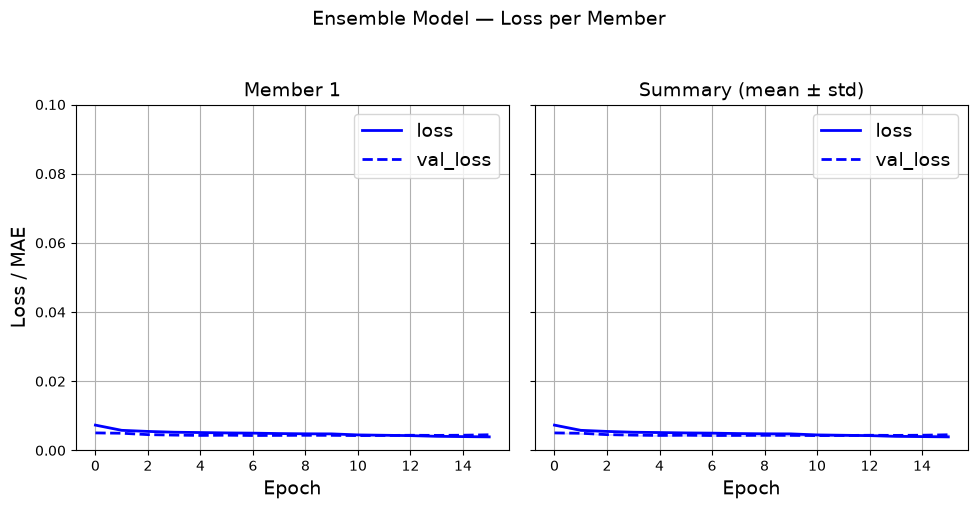

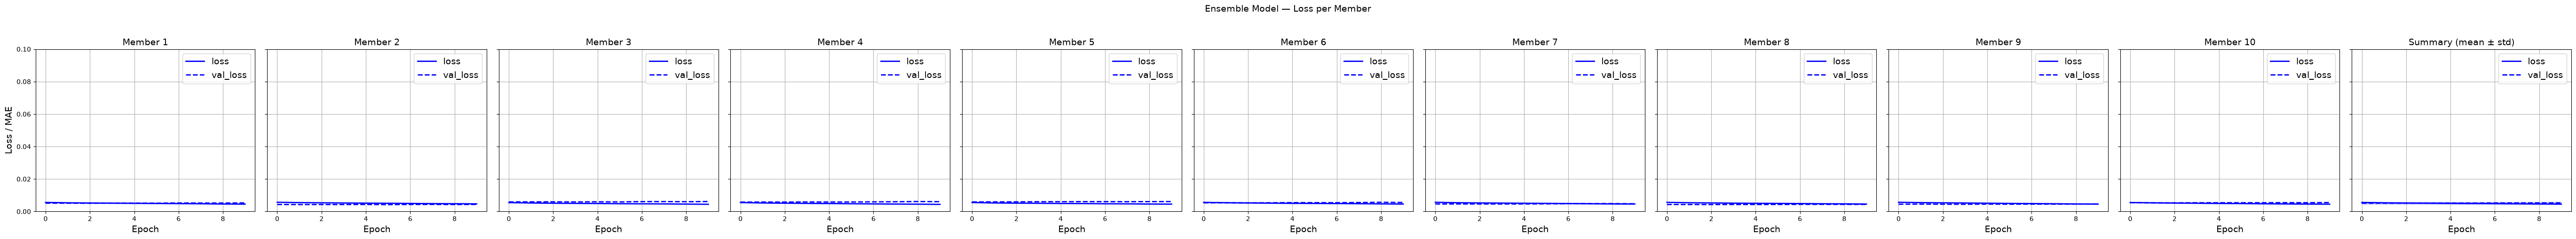

saved outputs/znn_pretrained_popcosmos_noisy_kfold_frombase/pz_challenge_taskset_3_cardinal_pz_model_1yr.pkl

========== task set 3: cardinal_10yr ==========
spec-selected: 63.4%, COSMOS-only: 36.6%; many-band vs spec-z on 4359 overlap objects: bias -0.0001, scatter 0.0132, |dz|>0.2 rate 0.0083

=== Base model, on all objects with the photometry as given ===
Epoch 1/100


I0000 00:00:1793229173.233078  549063 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_149580__.37


250/250 - 5s - 20ms/step - loss: 0.0059 - val_loss: 0.0035 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 3ms/step - loss: 0.0051 - val_loss: 0.0033 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 3ms/step - loss: 0.0049 - val_loss: 0.0032 - learning_rate: 0.0010
Epoch 4/100
250/250 - 1s - 3ms/step - loss: 0.0048 - val_loss: 0.0032 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 3ms/step - loss: 0.0047 - val_loss: 0.0032 - learning_rate: 0.0010
Epoch 6/100
250/250 - 1s - 3ms/step - loss: 0.0047 - val_loss: 0.0031 - learning_rate: 0.0010
Epoch 7/100
250/250 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0032 - learning_rate: 0.0010
Epoch 8/100
250/250 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0031 - learning_rate: 0.0010
Epoch 9/100

Epoch 9: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0031 - learning_rate: 0.0010
Epoch 10/100
250/250 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0030 - learning_rate: 

I0000 00:00:1793229191.347435  549065 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_170386__.38
I0000 00:00:1793229193.592187  549063 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_170386__.38


282/282 - 7s - 24ms/step - loss: 0.0047 - val_loss: 0.0034
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0034
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0034
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0034
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0035
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0034
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0035
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0035
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0035
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 0.0042 - val_loss: 0.0035

--- Member 2/10 (its own noise realization) ---
Epoch 1/10


...

282/282 - 7s - 25ms/step - loss: 0.0046 - val_loss: 0.0042
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0042
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0042
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0042
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0043
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0043
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 0.0042 - val_loss: 0.0043
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 0.0042 - val_loss: 0.0043
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 0.0041 - val_loss: 0.0043
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 0.0041 - val_loss: 0.0043

--- Member 9/10 (its own noise realization) ---
Epoch 1/10


I0000 00:00:1793229306.797811  549066 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_271962__.38
I0000 00:00:1793229309.214647  549067 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_271962__.38


282/282 - 7s - 25ms/step - loss: 0.0046 - val_loss: 0.0041
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0041
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0041
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0041
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0041
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0041
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 0.0042 - val_loss: 0.0041
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 0.0042 - val_loss: 0.0041
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 0.0042 - val_loss: 0.0040
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 0.0042 - val_loss: 0.0041

--- Member 10/10 (its own noise realization) ---
Epoch 1/10


I0000 00:00:1793229321.377744  549067 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_284659__.38
I0000 00:00:1793229323.754074  549063 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_284659__.38


282/282 - 7s - 26ms/step - loss: 0.0046 - val_loss: 0.0047
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0047
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0048
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0047
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0048
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 0.0042 - val_loss: 0.0048
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 0.0042 - val_loss: 0.0048
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 0.0041 - val_loss: 0.0048
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 0.0041 - val_loss: 0.0049
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 0.0041 - val_loss: 0.0048


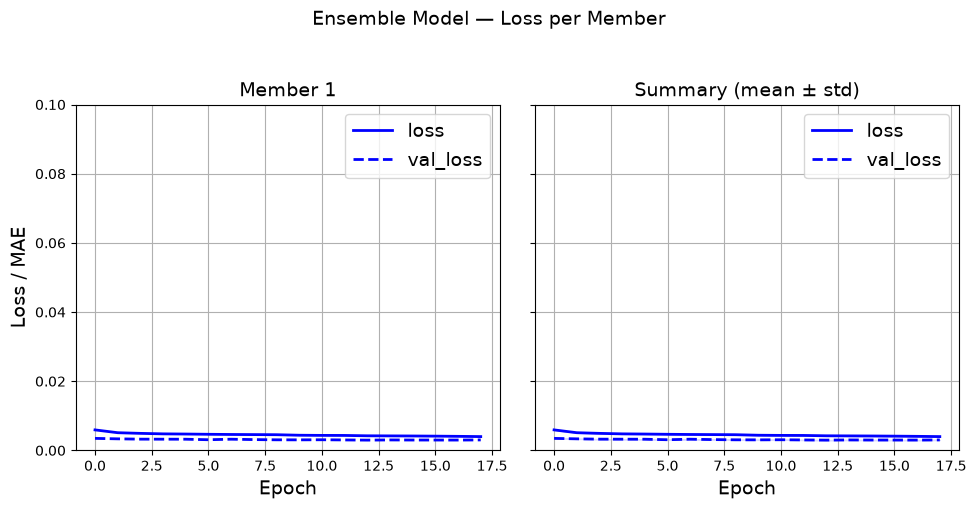

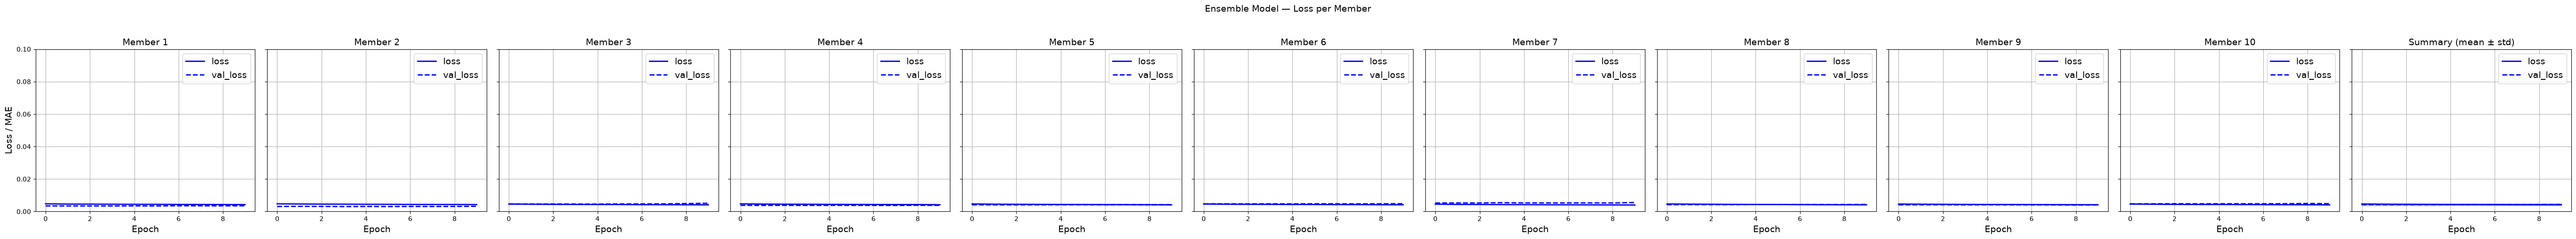

saved outputs/znn_pretrained_popcosmos_noisy_kfold_frombase/pz_challenge_taskset_3_cardinal_pz_model_10yr.pkl

========== task set 3: flagship_1yr ==========
spec-selected: 47.5%, COSMOS-only: 52.5%; many-band vs spec-z on 5479 overlap objects: bias 0.0001, scatter 0.0128, |dz|>0.2 rate 0.0073

=== Base model, on all objects with the photometry as given ===
Epoch 1/100


I0000 00:00:1793229360.677563  549067 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_298048__.37


250/250 - 5s - 21ms/step - loss: 0.0102 - val_loss: 0.0080 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 3ms/step - loss: 0.0084 - val_loss: 0.0079 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 3ms/step - loss: 0.0081 - val_loss: 0.0076 - learning_rate: 0.0010
Epoch 4/100
250/250 - 1s - 3ms/step - loss: 0.0079 - val_loss: 0.0076 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 3ms/step - loss: 0.0077 - val_loss: 0.0077 - learning_rate: 0.0010
Epoch 6/100

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 3ms/step - loss: 0.0076 - val_loss: 0.0076 - learning_rate: 0.0010
Epoch 7/100
250/250 - 1s - 3ms/step - loss: 0.0072 - val_loss: 0.0074 - learning_rate: 5.0000e-04
Epoch 8/100
250/250 - 1s - 3ms/step - loss: 0.0071 - val_loss: 0.0074 - learning_rate: 5.0000e-04
Epoch 9/100
250/250 - 1s - 3ms/step - loss: 0.0070 - val_loss: 0.0074 - learning_rate: 5.0000e-04
Epoch 10/100

Epoch 10: ReduceLROnPlateau reducing learning rate to 0.000250

/global/u2/j/jaimerz/UCL/mlpz_cnn_deepset/znn/data.py:158: RuntimeWarning: invalid value encountered in subtract
  mags_normed = mags - mag_i[None, :]  # normalize by i-band mag, per band, before binning


Epoch 1/10


...

282/282 - 7s - 26ms/step - loss: 0.0091 - val_loss: 0.0084
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0087 - val_loss: 0.0084
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 0.0085 - val_loss: 0.0086
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 0.0082 - val_loss: 0.0088
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 0.0081 - val_loss: 0.0085
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 0.0080 - val_loss: 0.0087
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 0.0078 - val_loss: 0.0087
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 0.0076 - val_loss: 0.0086
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 0.0075 - val_loss: 0.0086
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 0.0073 - val_loss: 0.0087

--- Member 9/10 (its own noise realization) ---
Epoch 1/10


I0000 00:00:1793229497.267348  549065 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_421301__.38
I0000 00:00:1793229499.598678  549067 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_421301__.38


282/282 - 7s - 26ms/step - loss: 0.0090 - val_loss: 0.0091
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0086 - val_loss: 0.0089
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 0.0084 - val_loss: 0.0088
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 0.0082 - val_loss: 0.0088
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 0.0081 - val_loss: 0.0089
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 0.0079 - val_loss: 0.0090
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 0.0077 - val_loss: 0.0091
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 0.0076 - val_loss: 0.0091
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 0.0075 - val_loss: 0.0092
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 0.0074 - val_loss: 0.0092

--- Member 10/10 (its own noise realization) ---
Epoch 1/10


I0000 00:00:1793229512.040572  549065 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_433998__.38
I0000 00:00:1793229514.402309  549066 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_433998__.38


282/282 - 7s - 26ms/step - loss: 0.0091 - val_loss: 0.0078
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0086 - val_loss: 0.0079
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 0.0085 - val_loss: 0.0079
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 0.0083 - val_loss: 0.0080
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 0.0081 - val_loss: 0.0081
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 0.0080 - val_loss: 0.0080
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 0.0078 - val_loss: 0.0080
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 0.0077 - val_loss: 0.0082
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 0.0075 - val_loss: 0.0083
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 0.0075 - val_loss: 0.0084


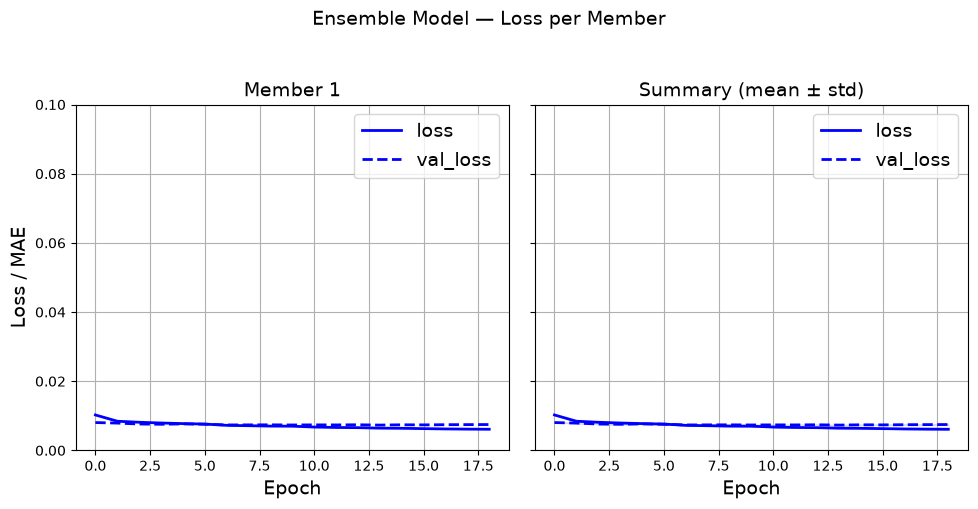

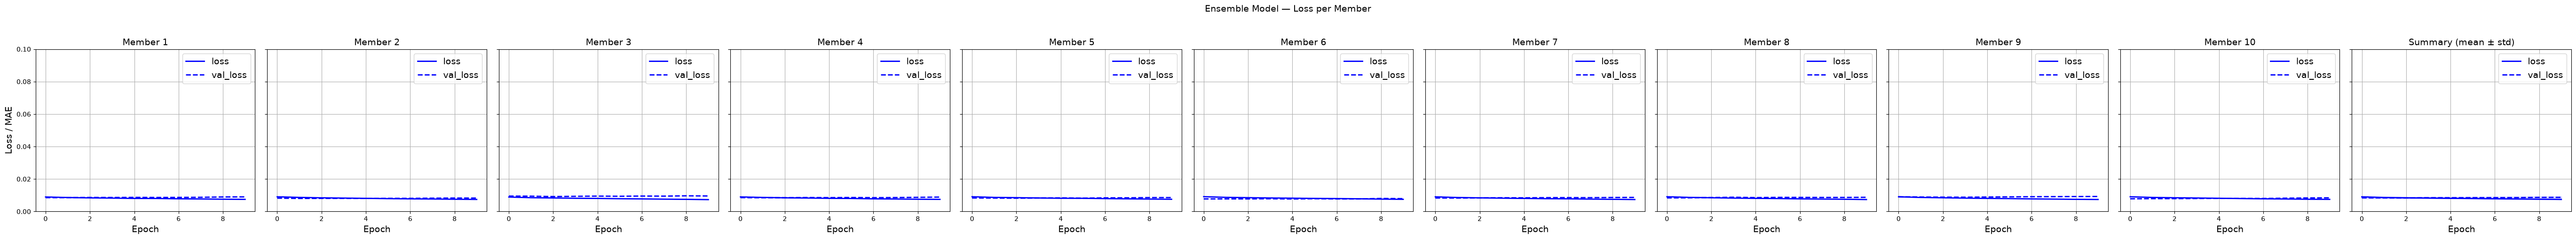

saved outputs/znn_pretrained_popcosmos_noisy_kfold_frombase/pz_challenge_taskset_3_flagship_pz_model_1yr.pkl

========== task set 3: flagship_10yr ==========
spec-selected: 45.5%, COSMOS-only: 54.5%; many-band vs spec-z on 5396 overlap objects: bias 0.0004, scatter 0.0128, |dz|>0.2 rate 0.0072

=== Base model, on all objects with the photometry as given ===
Epoch 1/100


I0000 00:00:1793229577.098873  549067 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_447387__.37


250/250 - 5s - 22ms/step - loss: 0.0073 - val_loss: 0.0061 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 3ms/step - loss: 0.0066 - val_loss: 0.0057 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 3ms/step - loss: 0.0065 - val_loss: 0.0056 - learning_rate: 0.0010
Epoch 4/100
250/250 - 1s - 3ms/step - loss: 0.0063 - val_loss: 0.0055 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 3ms/step - loss: 0.0063 - val_loss: 0.0054 - learning_rate: 0.0010
Epoch 6/100
250/250 - 1s - 3ms/step - loss: 0.0062 - val_loss: 0.0054 - learning_rate: 0.0010
Epoch 7/100
250/250 - 1s - 3ms/step - loss: 0.0062 - val_loss: 0.0056 - learning_rate: 0.0010
Epoch 8/100
250/250 - 1s - 3ms/step - loss: 0.0062 - val_loss: 0.0056 - learning_rate: 0.0010
Epoch 9/100

Epoch 9: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 3ms/step - loss: 0.0061 - val_loss: 0.0054 - learning_rate: 0.0010
Epoch 10/100
250/250 - 1s - 3ms/step - loss: 0.0060 - val_loss: 0.0054 - learning_rate: 

I0000 00:00:1793229590.548114  549067 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_461332__.38
I0000 00:00:1793229592.835692  549065 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_461332__.38


282/282 - 7s - 25ms/step - loss: 0.0068 - val_loss: 0.0070
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0066 - val_loss: 0.0069
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 0.0065 - val_loss: 0.0070
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 0.0065 - val_loss: 0.0069
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 0.0064 - val_loss: 0.0069
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 0.0063 - val_loss: 0.0069
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 0.0063 - val_loss: 0.0069
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 0.0062 - val_loss: 0.0069
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 0.0062 - val_loss: 0.0069
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 0.0061 - val_loss: 0.0069

--- Member 2/10 (its own noise realization) ---
Epoch 1/10


...

282/282 - 7s - 26ms/step - loss: 0.0068 - val_loss: 0.0067
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0066 - val_loss: 0.0067
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 0.0066 - val_loss: 0.0067
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 0.0065 - val_loss: 0.0067
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 0.0065 - val_loss: 0.0067
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 0.0064 - val_loss: 0.0068
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 0.0064 - val_loss: 0.0068
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 0.0063 - val_loss: 0.0068
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 0.0063 - val_loss: 0.0068
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 0.0062 - val_loss: 0.0068

--- Member 9/10 (its own noise realization) ---
Epoch 1/10


I0000 00:00:1793229707.821771  549065 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_562908__.38
I0000 00:00:1793229710.127837  549067 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_562908__.38


282/282 - 7s - 25ms/step - loss: 0.0068 - val_loss: 0.0065
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0067 - val_loss: 0.0065
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 0.0066 - val_loss: 0.0065
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 0.0066 - val_loss: 0.0065
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 0.0065 - val_loss: 0.0065
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 0.0064 - val_loss: 0.0066
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 0.0064 - val_loss: 0.0066
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 0.0063 - val_loss: 0.0066
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 0.0063 - val_loss: 0.0065
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 0.0063 - val_loss: 0.0066

--- Member 10/10 (its own noise realization) ---
Epoch 1/10


I0000 00:00:1793229722.416333  549066 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_575605__.38
I0000 00:00:1793229724.740362  549064 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_575605__.38


282/282 - 7s - 25ms/step - loss: 0.0070 - val_loss: 0.0045
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0069 - val_loss: 0.0045
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 0.0068 - val_loss: 0.0045
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 0.0067 - val_loss: 0.0045
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 0.0066 - val_loss: 0.0046
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 0.0066 - val_loss: 0.0045
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 0.0065 - val_loss: 0.0045
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 0.0065 - val_loss: 0.0046
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 0.0065 - val_loss: 0.0045
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 0.0064 - val_loss: 0.0046


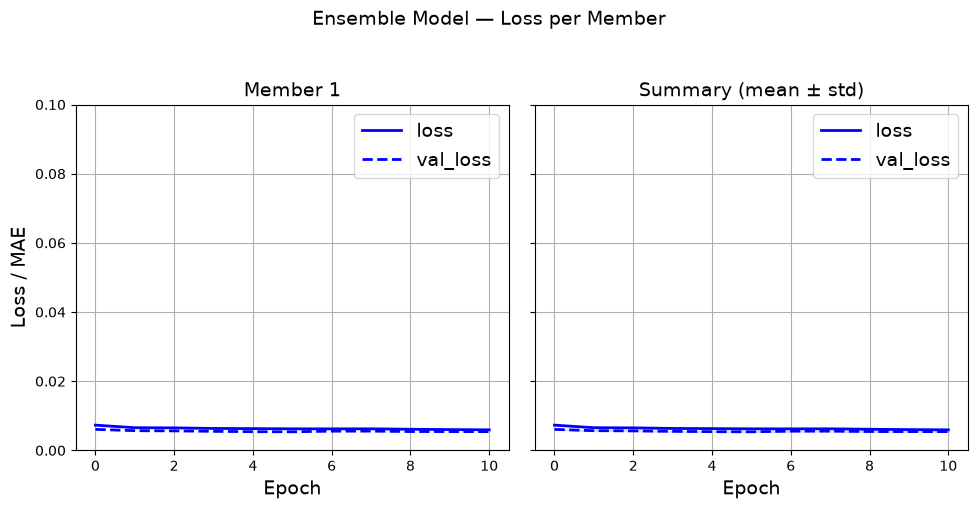

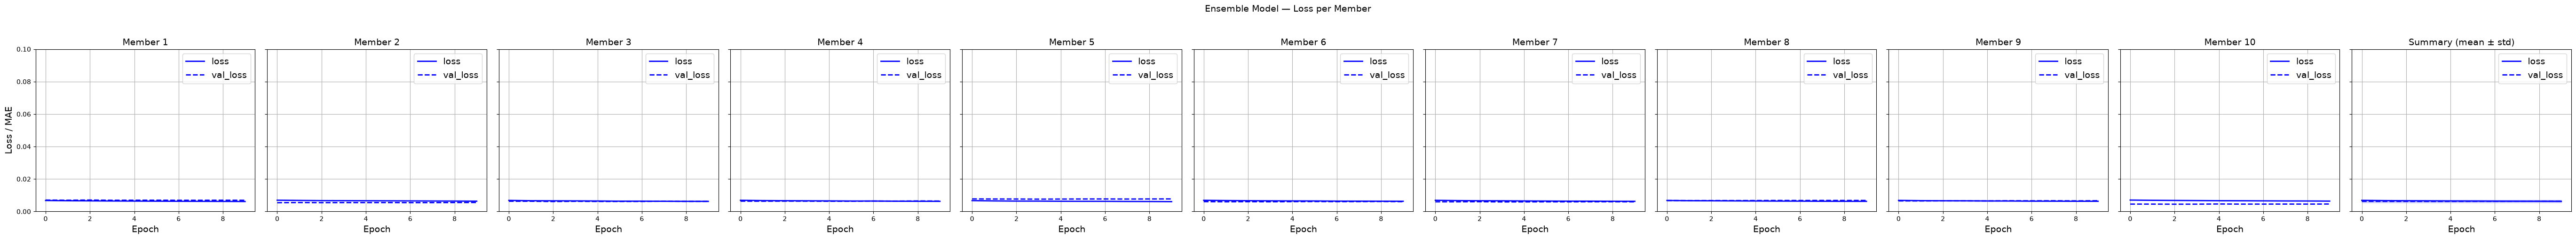

saved outputs/znn_pretrained_popcosmos_noisy_kfold_frombase/pz_challenge_taskset_3_flagship_pz_model_10yr.pkl


In [4]:
for SIM in SIMS:
    for SCENARIO in SCENARIOS:
        config = f"{SIM}_{SCENARIO}"
        print(f"\n========== task set {TASKSET}: {config} ==========")

        train_file = os.path.join(DATA_DIR, f"pz_challenge_taskset_{TASKSET}_{SIM}_training_{SCENARIO}.hdf5")
        train = znn.read_catalog(train_file)
        z_ref, _ = reference_redshifts(train)

        rng = np.random.default_rng(NOISE_SEED)
        # the held-out split is not used here, only kept out of training (pz_challenge_results.ipynb scores on it)
        idx_fit, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
        trained_models, histories, base_history = znn.train_from_catalog(
            znn.build_model, train.iloc[idx_fit], z_ref[idx_fit], BANDS, REF_BAND, FEATURE_CONFIG, errors=ERRORS, rng=rng,
            N_MEMBERS=N_MEMBERS, from_base=FROM_BASE, EPOCHS=EPOCHS, FINETUNE_EPOCHS=FINETUNE_EPOCHS,
            FINETUNE_LR=FINETUNE_LR, random_state=SEED, pretraining=PRETRAINING,
        )
        if base_history is not None:
            znn.plot_ensemble_losses([base_history], ylim=(0, 0.1))
        znn.plot_ensemble_losses(histories, ylim=(0, 0.1))

        # subtask 2 submission file: the trained ensemble
        model_file = os.path.join(OUT_DIR, f"pz_challenge_taskset_{TASKSET}_{SIM}_pz_model_{SCENARIO}.pkl")
        znn.save_ensemble_file(model_file, trained_models, BANDS, REF_BAND, FEATURE_CONFIG)
        print("saved", model_file)